# Encoder variants (v2: GA after the off-by-one fix)
Same LSTM encoder, optimizer, seeds, run split and triplet margin (`fit_encoder`); the triplets, the input orientation and the number of epochs change. The GA data come from the fixed GA (mutation and OX can use the last position, `cross_rate: 1.0`); the v1 results are kept in the tag `v1-wyniki` and in `outputs/v1`.

- `trajectory`: original objective (positive = next elite of the run, negative = tour of another run with a similar length);
- `trajectory_canonical`: the same, tours in canonical orientation (`perm[0] < perm[-1]`);
- `edge_canonical_100` (**base**): triplets of three elites ordered by edge distance (gap >= `min_gap`), canonical orientation, 100 epochs with patience only reported;
- `edge_local_canonical` (ablation): half of the triplets as in the base, half around the anchor (nearest elites or 1-3 random 2-opt moves / swaps);
- `edge_synthetic_canonical`: unlimited synthetic data: the anchor is a random tour (or, in 20% of triplets, a training elite), positive and negative are the anchor after 1-5 random 2-opt moves or swaps, ordered by their exact edge distance; 100 epochs as the base;
- `random init, canonical`: the untrained encoder (reference).

Evaluation sets: the validation runs of instance 1 (never seen in training) and instance 2 (TSP seed 99, no retraining). Edge-based metrics (recall@k, Spearman) are partly the training target of the edge variants; independent evidence: the funnel (`n_end`, `best_strength` against locations of the same size), `end_equal` against its chance level, and the run and generation probes.

Caches carry a config hash in their names (`outputs/trajectories_{hash}.npz`, `outputs/encoder_variant_{name}_{hash}.pt`); missing ones are generated / trained on the first run.

In [1]:
import os
from pathlib import Path

if Path.cwd().name == 'notebooks':
    os.chdir("..")

In [2]:
import numpy as np
import torch
from dl_permutations import encoder_variants as V
from dl_permutations import stn_clusters as S
from dl_permutations import stn_controls as K

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
data = S.drop_repeated_steps(S.load_or_generate_trajectories())
val_runs, _ = S.split_runs()
evaluation = {
    "instance 1, validation runs": V.runs_subset(data, val_runs),
    "instance 2 (TSP seed 99)": S.drop_repeated_steps(V.load_or_generate_instance(99)),
}
encoders = {
    "random init, canonical": (K.random_init_encoder(device), True),
    **{name: (V.load_or_fit_variant(name, data, device), spec["canonical"]) for name, spec in V.VARIANTS.items()},
}
ks = [f"k={k}" for k in S.STN_N_CENTERS]
for name, d in evaluation.items():
    print(f"{name}: {len(d['perm'])} elites, {len(np.unique(d['run_id']))} runs, "
          f"best tour length {d['fitness'].min():.3f}")

instance 1, validation runs: 392 elites, 20 runs, best tour length 41.979
instance 2 (TSP seed 99): 2001 elites, 100 runs, best tour length 38.457


## v1 vs v2: robustness of the key numbers (instance 1, all runs)
The same tables as in v1 for the permutation space, the original objective (`trajectory`) and the base edge variant, computed on the GA data before (v1, `outputs/v1`) and after the fix (v2); every encoder is trained on the data of its version.

In [3]:
base = ("trajectory", "edge_canonical_100")
data_v1, models_v1 = V.load_v1(base, device)
tables_v1, _ = V.stn_pivots(data_v1, {n: V.variant_embeddings(n, models_v1[n], data_v1["perm"], device) for n in base},
                            val_runs)
tables_v2, _ = V.stn_pivots(data, {n: V.variant_embeddings(n, encoders[n][0], data["perm"], device) for n in base},
                            val_runs)
print(f"elites: v1 {len(data_v1['perm'])}, v2 {len(data['perm'])} | best tour length: "
      f"v1 {data_v1['fitness'].min():.3f}, v2 {data['fitness'].min():.3f}", end="\n\n")
for metric, table in V.robustness_tables(tables_v1, tables_v2).items():
    print(metric)
    print(S.format_table(table, ["encoder", *ks]), end="\n\n")

elites: v1 1854, v2 1910 | best tour length: v1 41.049, v2 40.809

ties
               encoder   k=5  k=10  k=20  k=50
permutation space (v1) 0.266 0.344 0.368 0.385
permutation space (v2) 0.155 0.230 0.338 0.375

n_end
                encoder k=5 k=10 k=20 k=50
 permutation space (v1)   4    7   11   23
 permutation space (v2)   2    4    6   17
        trajectory (v1)   5   10   19   38
        trajectory (v2)   5   10   17   30
edge_canonical_100 (v1)   3    7    8   18
edge_canonical_100 (v2)   1    2    4   13

best_strength
                encoder   k=5  k=10  k=20  k=50
 permutation space (v1) 0.970 0.950 0.820 0.440
 permutation space (v2) 0.960 0.980 0.950 0.520
        trajectory (v1) 0.510 0.300 0.280 0.110
        trajectory (v2) 0.600 0.410 0.280 0.120
edge_canonical_100 (v1) 1.000 0.950 0.680 0.230
edge_canonical_100 (v2) 0.980 0.990 0.810 0.340

ari
                         encoder   k=5  k=10  k=20  k=50
                 trajectory (v1) 0.007 0.010 0.022 0.036
         

## Geometry and probes
`recall@5`, `recall@10` (distinct cycles): share of a tour's k nearest tours in the embedding that lie within its k-th smallest edge distance. `spearman`: rank correlation of embedding and edge distances over all pairs. `rev_ratio`: distance to the own reversal / median pair distance. `run_acc`, `gen_r2`: linear probes for run identity (stratified folds within runs) and generation (folds grouped by run). `edge incidence` is the permutation space itself, `chance` a random ranking and probes without features.

In [4]:
Z = {}
for set_name, d in evaluation.items():
    Z[set_name] = {name: V.embed_tours(model, d["perm"], device, canonical) for name, (model, canonical) in encoders.items()}
    Z_rev = {name: V.embed_tours(model, K.reverse_tours(d["perm"]), device, canonical)
             for name, (model, canonical) in encoders.items()}
    rows, chance = V.geometry_rows(Z[set_name], d, Z_rev)
    print(f"{set_name}: {chance['distinct_cycles']} distinct cycles")
    print(S.format_table(rows, V.GEOMETRY_COLUMNS), end="\n\n")

instance 1, validation runs: 392 distinct cycles
                   encoder recall@5 recall@10 spearman rev_ratio run_acc gen_r2
    random init, canonical    0.353     0.306    0.159     0.000   0.554 -0.191
                trajectory    0.385     0.334    0.071     1.220   0.707 -0.481
      trajectory_canonical    0.351     0.289    0.083     0.000   0.625 -0.543
        edge_canonical_100    0.398     0.404    0.759     0.000   0.327  0.492
      edge_local_canonical    0.405     0.417    0.737     0.000   0.449  0.447
  edge_synthetic_canonical    0.292     0.274    0.633     0.000   0.349  0.626
edge incidence (reference)    1.000     1.000    1.000     0.000   0.786 -0.121
                    chance    0.021     0.041      nan       nan   0.077 -0.006



instance 2 (TSP seed 99): 1997 distinct cycles
                   encoder recall@5 recall@10 spearman rev_ratio run_acc gen_r2
    random init, canonical    0.321     0.255    0.078     0.000   0.393  0.112
                trajectory    0.323     0.250    0.054     1.164   0.553  0.028
      trajectory_canonical    0.312     0.234    0.053     0.000   0.468  0.058
        edge_canonical_100    0.233     0.188    0.234     0.000   0.230  0.079
      edge_local_canonical    0.223     0.182    0.235     0.000   0.247  0.174
  edge_synthetic_canonical    0.232     0.197    0.383     0.000   0.296  0.243
edge incidence (reference)    1.000     1.000    1.000     0.000   0.720  0.601
                    chance    0.004     0.009      nan       nan   0.014 -0.005



## STN agreement with the permutation space
Centers drawn from the elites of each evaluation set; one row per encoder, one column per k. ARI / AMI with the ceiling of the permutation space against itself under random tie-breaking; `end_equal`; `n_end` and `best_strength` with the permutation-space row; `ties`: share of tied elites. Funnel comparisons are robust to tie-breaking for k <= 10 only.

In [5]:
results = {}
for set_name, d in evaluation.items():
    print(f"===== {set_name}")
    tables, results[set_name] = V.stn_pivots(d, Z[set_name], val_runs)
    for metric, table in tables.items():
        print(metric)
        print(S.format_table(table, ["encoder", *ks]), end="\n\n")

===== instance 1, validation runs


ari
                    encoder   k=5  k=10  k=20  k=50
     random init, canonical 0.015 0.018 0.051 0.135
                 trajectory 0.030 0.067 0.052 0.117
       trajectory_canonical 0.005 0.033 0.052 0.122
         edge_canonical_100 0.156 0.129 0.119 0.146
       edge_local_canonical 0.179 0.163 0.151 0.181
   edge_synthetic_canonical 0.020 0.030 0.058 0.085
ceiling (perm, random ties) 0.654 0.661 0.667 0.605

ami
                    encoder   k=5  k=10  k=20  k=50
     random init, canonical 0.022 0.050 0.138 0.242
                 trajectory 0.031 0.092 0.129 0.234
       trajectory_canonical 0.010 0.055 0.122 0.238
         edge_canonical_100 0.146 0.164 0.213 0.264
       edge_local_canonical 0.173 0.212 0.252 0.289
   edge_synthetic_canonical 0.049 0.062 0.143 0.164
ceiling (perm, random ties) 0.650 0.703 0.742 0.715

end_equal
                 encoder   k=5  k=10  k=20  k=50
  random init, canonical 0.300 0.300 0.250 0.500
              trajectory 0.500 0.450 0.300 0.450
 

ari
                    encoder    k=5  k=10  k=20  k=50
     random init, canonical  0.010 0.008 0.017 0.028
                 trajectory -0.001 0.013 0.020 0.024
       trajectory_canonical  0.001 0.005 0.009 0.021
         edge_canonical_100  0.065 0.055 0.034 0.023
       edge_local_canonical  0.044 0.031 0.023 0.025
   edge_synthetic_canonical  0.037 0.035 0.030 0.027
ceiling (perm, random ties)  0.694 0.680 0.619 0.624

ami
                    encoder   k=5  k=10  k=20  k=50
     random init, canonical 0.016 0.024 0.053 0.110
                 trajectory 0.004 0.026 0.054 0.099
       trajectory_canonical 0.003 0.009 0.027 0.084
         edge_canonical_100 0.034 0.054 0.071 0.087
       edge_local_canonical 0.044 0.048 0.070 0.090
   edge_synthetic_canonical 0.033 0.051 0.072 0.099
ceiling (perm, random ties) 0.664 0.677 0.667 0.693

end_equal
                 encoder   k=5  k=10  k=20  k=50
  random init, canonical 0.170 0.150 0.170 0.110
              trajectory 0.260 0.260 0.190

## Funnel against locations of the same size, end_equal against chance
`best_strength` of the best location (share of runs entering it) against the mean entry share of the other locations whose share of elites is within a factor 2 of the best location's (at least the 3 closest in size), [share of those locations the best one beats]; the second table shows the sizes compared. `end_equal / chance`: chance = sum over locations of p_perm * p_emb of the final locations.

In [6]:
for set_name, d in evaluation.items():
    print(f"===== {set_name}")
    for metric, table in V.funnel_pivots(results[set_name], d).items():
        print(metric)
        print(S.format_table(table, ["encoder", *ks]), end="\n\n")

===== instance 1, validation runs
best_strength vs size-matched locations [share beaten]
                 encoder                 k=5                k=10                k=20                k=50
       permutation space 1.00 vs 0.77 [1.00] 0.85 vs 0.78 [0.83] 0.65 vs 0.60 [0.60] 0.20 vs 0.11 [0.90]
  random init, canonical 0.80 vs 0.73 [0.67] 0.75 vs 0.58 [0.71] 0.40 vs 0.41 [0.31] 0.25 vs 0.19 [0.78]
              trajectory 0.70 vs 0.66 [0.50] 0.45 vs 0.47 [0.42] 0.45 vs 0.35 [0.82] 0.10 vs 0.14 [0.24]
    trajectory_canonical 0.85 vs 0.77 [0.88] 0.75 vs 0.57 [0.94] 0.35 vs 0.35 [0.53] 0.10 vs 0.13 [0.33]
      edge_canonical_100 1.00 vs 0.87 [1.00] 0.90 vs 0.68 [0.67] 0.65 vs 0.56 [0.72] 0.20 vs 0.18 [0.61]
    edge_local_canonical 1.00 vs 0.87 [1.00] 0.75 vs 0.71 [0.60] 0.55 vs 0.51 [0.65] 0.15 vs 0.17 [0.48]
edge_synthetic_canonical 0.85 vs 0.84 [0.50] 0.70 vs 0.62 [0.62] 0.35 vs 0.48 [0.23] 0.05 vs 0.21 [0.02]

share of elites: best location vs references
                 encoder 

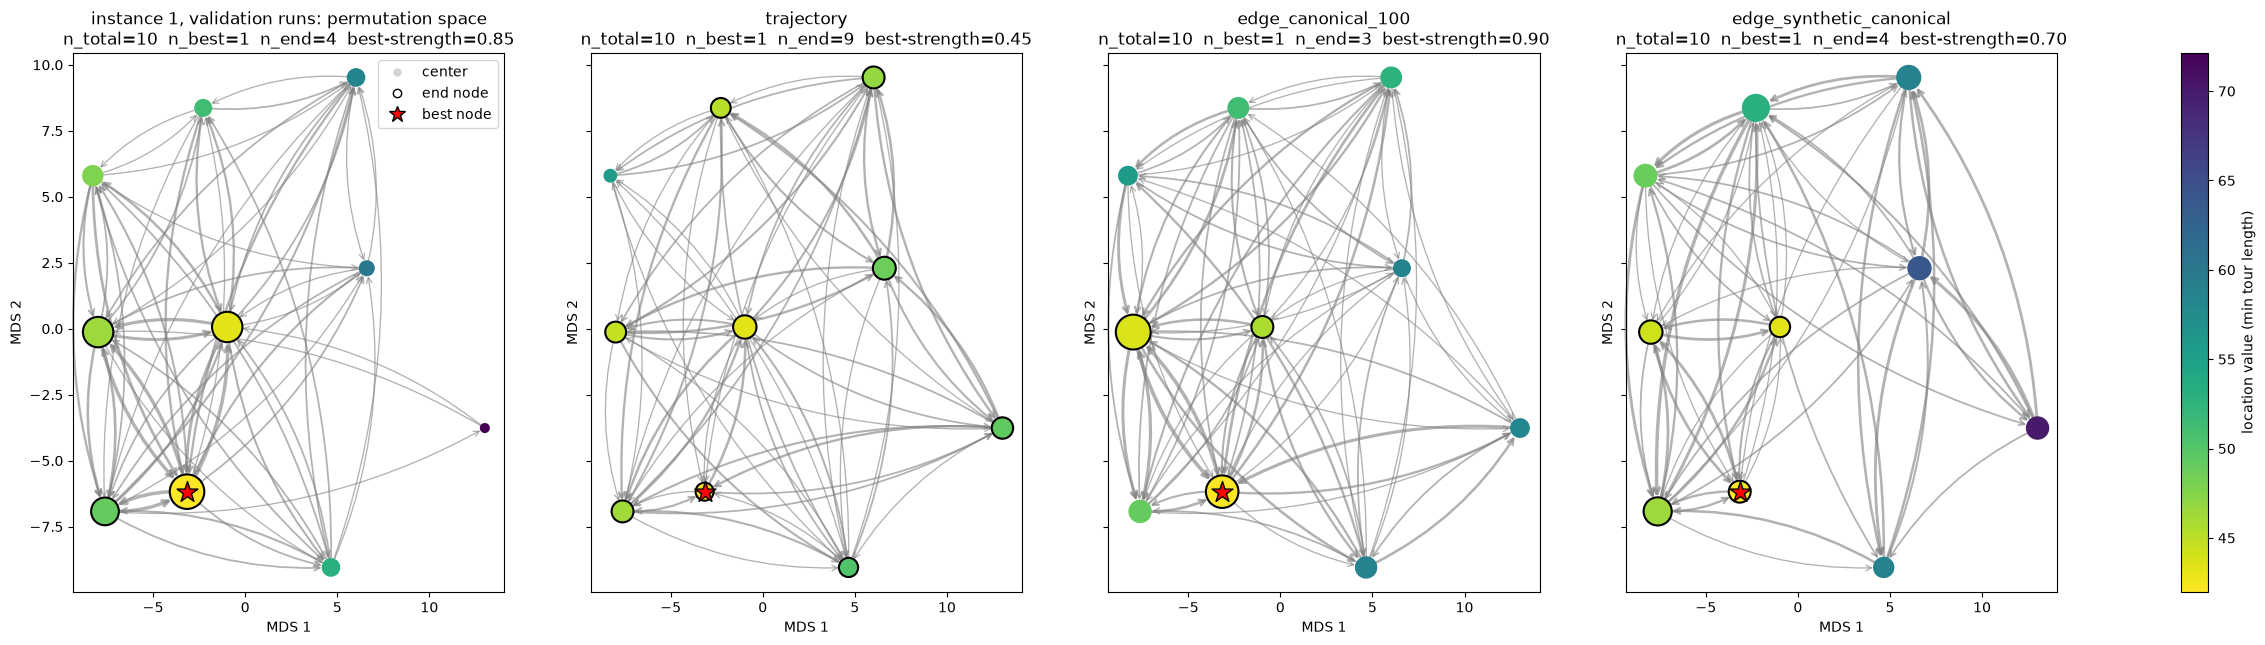

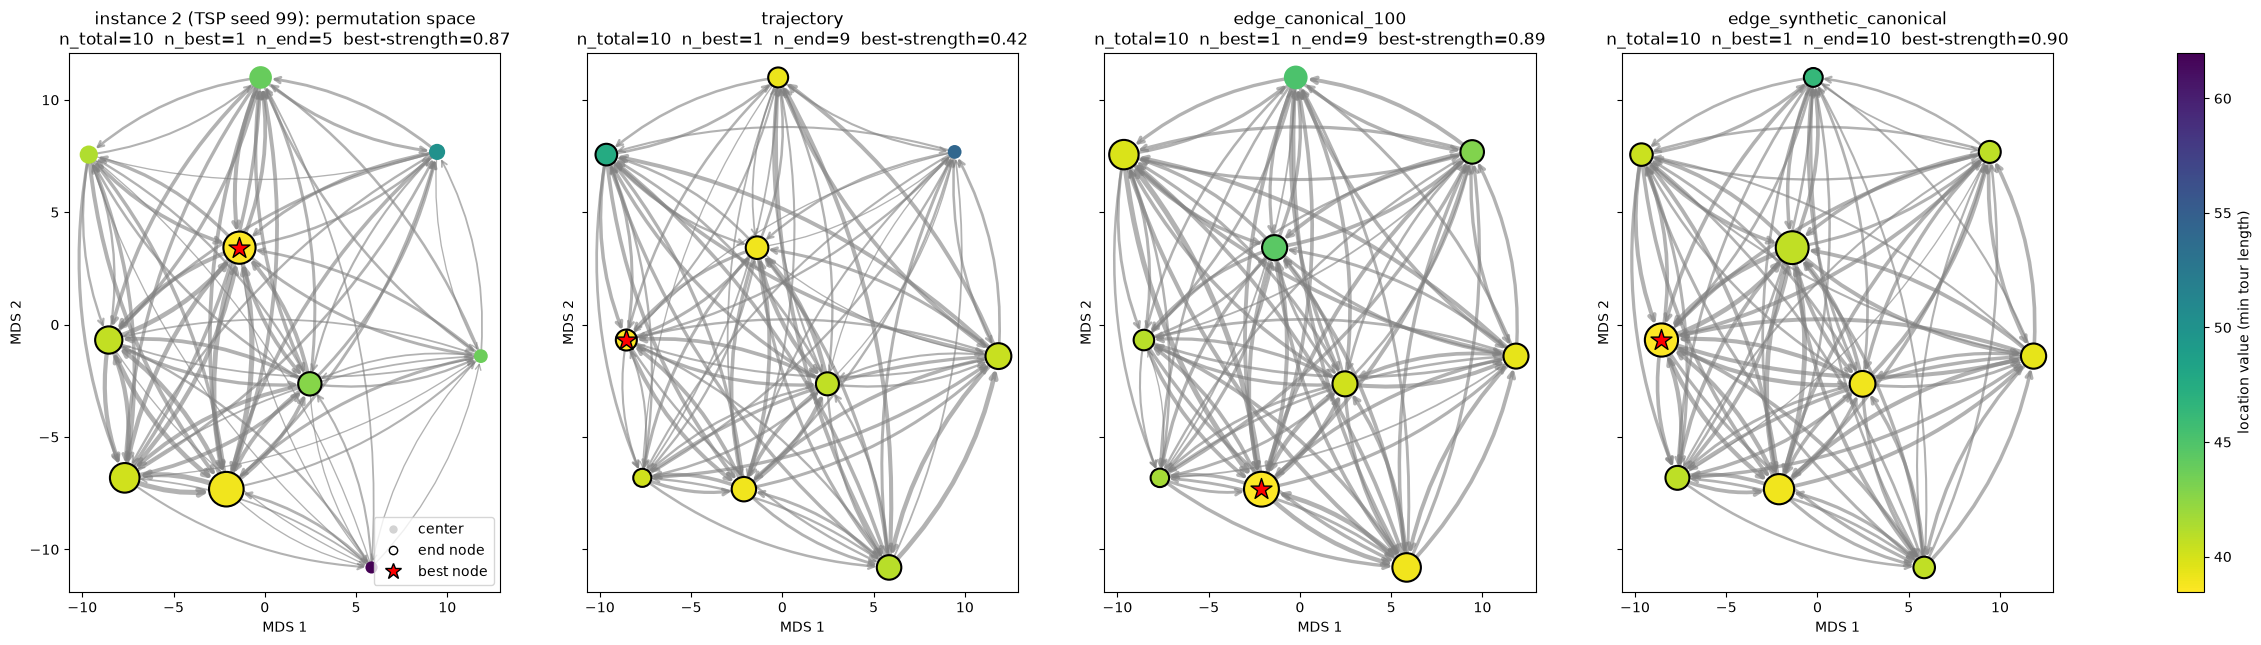

In [7]:
names = ("trajectory", "edge_canonical_100", "edge_synthetic_canonical")
for set_name in evaluation:
    res = results[set_name]["random init, canonical", 10]
    S.plot_stns((res["G_perm"], *(results[set_name][name, 10]["G_emb"] for name in names)),
                (f"{set_name}: permutation space", *(f"{name}" for name in names)), res["pos"])